In [1]:
!pip install roboflow --quiet
 
from roboflow import Roboflow
 
rf = Roboflow(api_key="DRPHvV7kONHOrQxmSqFa")
project = rf.workspace("thayakar-ed3it").project("sugarcane-aht9u")
version = project.version(1)
dataset = version.download("folder")
 
print("Downloaded to:", dataset.location)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 67.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 109.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to sugarcane-1 in folder:: 100%|██████████| 4613/4613 [00:00<00:00, 7315.04it/s]

Downloaded to: /kaggle/working/sugarcane-1


In [2]:
import os
 
def show_tree(path, max_depth=3, prefix=""):
    if max_depth < 0:
        return
    try:
        entries = sorted(os.listdir(path))
    except Exception as e:
        print(f"{prefix}[ERROR] {e}")
        return
    for entry in entries:
        full = os.path.join(path, entry)
        if os.path.isdir(full):
            n_files = len([f for f in os.listdir(full) if os.path.isfile(os.path.join(full, f))])
            print(f"{prefix}{entry}/  ({n_files} files)")
            show_tree(full, max_depth - 1, prefix + "    ")

print("=== Roboflow Downloaded Dataset Structure ===")
show_tree(dataset.location, max_depth=3)

=== Roboflow Downloaded Dataset Structure ===
test/  (0 files)
    Bacterial Blight/  (86 files)
    Healthy/  (71 files)
    Mosaic/  (64 files)
    RedRot/  (71 files)
    Rust/  (84 files)
    Yellow/  (82 files)
train/  (0 files)
    Bacterial Blight/  (558 files)
    Healthy/  (513 files)
    Mosaic/  (503 files)
    RedRot/  (571 files)
    Rust/  (516 files)
    Yellow/  (552 files)
valid/  (0 files)
    Bacterial Blight/  (156 files)
    Healthy/  (170 files)
    Mosaic/  (147 files)
    RedRot/  (158 files)
    Rust/  (133 files)
    Yellow/  (155 files)


In [3]:
EXISTING_SUGARCANE_DIR = "/kaggle/input/datasets/nirmalsankalana/sugarcane-leaf-disease-dataset"  # <-- CHANGE IF NEEDED
 
print("=== Your Existing Kaggle Sugarcane Dataset ===")
show_tree(EXISTING_SUGARCANE_DIR, max_depth=3)

=== Your Existing Kaggle Sugarcane Dataset ===
Healthy/  (522 files)
Mosaic/  (462 files)
RedRot/  (518 files)
Rust/  (514 files)
Yellow/  (505 files)


In [4]:
CLASS_NAME_MAP = {
    # normalize variations -> final class name
    "healthy":          "Healthy",
    "yellow":           "Yellow",
    "rust":             "Rust",
    "mosaic":           "Mosaic",
    "redrot":           "RedRot",
    "red_rot":          "RedRot",
    "red rot":          "RedRot",
    "bacterialblight":  "BacterialBlight",
    "bacterial_blight": "BacterialBlight",
    "bacterial blight": "BacterialBlight",
}


In [5]:
def normalize_class_name(folder_name):
    key = folder_name.strip().lower().replace("-", "").replace(" ", "")
    key = key.replace("_", "")
    # try direct match against normalized map keys
    for map_key, final_name in CLASS_NAME_MAP.items():
        if map_key.replace("_", "").replace(" ", "") == key:
            return final_name
    # fallback: return as-is (title case) so nothing silently disappears
    print(f"  [WARNING] Unrecognized class folder name: '{folder_name}' -- kept as-is")
    return folder_name.strip()


In [6]:
def find_class_folders(root_dir):
    """
    Walks the dataset directory and returns {normalized_class_name: [list of folder paths]}
    Handles both flat structure (root/ClassName/*.jpg) and
    split structure (root/train/ClassName/*.jpg, root/valid/..., root/test/...).
    """
    class_folders = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        image_files = [f for f in filenames if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        if len(image_files) > 0:
            folder_name = os.path.basename(dirpath)
            # skip generic split folder names themselves
            if folder_name.lower() in ("train", "valid", "test", "images"):
                continue
            normalized = normalize_class_name(folder_name)
            class_folders.setdefault(normalized, []).append(dirpath)
    return class_folders

print("=== Scanning Roboflow dataset for class folders ===")
roboflow_classes = find_class_folders(dataset.location)
for cls, folders in roboflow_classes.items():
    total_imgs = sum(len([f for f in os.listdir(p) if f.lower().endswith((".jpg",".jpeg",".png"))]) for p in folders)
    print(f"  {cls}: {total_imgs} images across {len(folders)} folder(s)")

print()
print("=== Scanning existing Kaggle dataset for class folders ===")
existing_classes = find_class_folders(EXISTING_SUGARCANE_DIR)
for cls, folders in existing_classes.items():
    total_imgs = sum(len([f for f in os.listdir(p) if f.lower().endswith((".jpg",".jpeg",".png"))]) for p in folders)
    print(f"  {cls}: {total_imgs} images across {len(folders)} folder(s)")

=== Scanning Roboflow dataset for class folders ===
  Rust: 733 images across 3 folder(s)
  RedRot: 800 images across 3 folder(s)
  Mosaic: 714 images across 3 folder(s)
  Healthy: 754 images across 3 folder(s)
  Yellow: 789 images across 3 folder(s)
  BacterialBlight: 800 images across 3 folder(s)

=== Scanning existing Kaggle dataset for class folders ===
  Yellow: 505 images across 1 folder(s)
  Mosaic: 462 images across 1 folder(s)
  Healthy: 522 images across 1 folder(s)
  RedRot: 518 images across 1 folder(s)
  Rust: 514 images across 1 folder(s)


In [7]:
import hashlib

def file_hash(filepath):
    """Fast partial hash -- reads first 64KB, good enough to catch exact duplicates."""
    h = hashlib.md5()
    with open(filepath, "rb") as f:
        h.update(f.read(65536))
    return h.hexdigest()

def hash_all_images(folder_list):
    """Returns {hash: filepath} for all images across a list of folders."""
    hashes = {}
    for folder in folder_list:
        for fname in os.listdir(folder):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                fpath = os.path.join(folder, fname)
                try:
                    hashes[file_hash(fpath)] = fpath
                except Exception:
                    pass
    return hashes

print("=== Checking for duplicate images between sources ===")
all_classes = set(list(roboflow_classes.keys()) + list(existing_classes.keys()))

duplicate_report = {}
for cls in sorted(all_classes):
    existing_hashes = hash_all_images(existing_classes.get(cls, []))
    roboflow_hashes  = hash_all_images(roboflow_classes.get(cls, []))

    dupes = set(existing_hashes.keys()) & set(roboflow_hashes.keys())
    unique_new = set(roboflow_hashes.keys()) - set(existing_hashes.keys())

    duplicate_report[cls] = {
        "existing_count": len(existing_hashes),
        "roboflow_count": len(roboflow_hashes),
        "duplicate_count": len(dupes),
        "unique_new_count": len(unique_new),
    }

    print(f"\n{cls}:")
    print(f"  Existing images:        {len(existing_hashes)}")
    print(f"  Roboflow images:        {len(roboflow_hashes)}")
    print(f"  Duplicates (skip these): {len(dupes)}")
    print(f"  Unique NEW images to add: {len(unique_new)}")

=== Checking for duplicate images between sources ===

BacterialBlight:
  Existing images:        0
  Roboflow images:        800
  Duplicates (skip these): 0
  Unique NEW images to add: 800

Healthy:
  Existing images:        476
  Roboflow images:        754
  Duplicates (skip these): 0
  Unique NEW images to add: 754

Mosaic:
  Existing images:        376
  Roboflow images:        714
  Duplicates (skip these): 0
  Unique NEW images to add: 714

RedRot:
  Existing images:        518
  Roboflow images:        800
  Duplicates (skip these): 0
  Unique NEW images to add: 800

Rust:
  Existing images:        447
  Roboflow images:        733
  Duplicates (skip these): 0
  Unique NEW images to add: 733

Yellow:
  Existing images:        494
  Roboflow images:        789
  Duplicates (skip these): 0
  Unique NEW images to add: 789


In [8]:
import shutil

FINAL_DIR = "/kaggle/working/sugarcane_merged"
os.makedirs(FINAL_DIR, exist_ok=True)

final_counts = {}

for cls in sorted(all_classes):
    cls_out_dir = os.path.join(FINAL_DIR, cls)
    os.makedirs(cls_out_dir, exist_ok=True)

    copied = 0

    # 1) Copy ALL existing images first (these are your trusted current dataset)
    for folder in existing_classes.get(cls, []):
        for fname in os.listdir(folder):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                src = os.path.join(folder, fname)
                dst = os.path.join(cls_out_dir, f"existing_{copied}_{fname}")
                shutil.copy2(src, dst)
                copied += 1

    existing_hashes_set = set(hash_all_images(existing_classes.get(cls, [])).keys())

    # 2) Copy only NEW unique images from Roboflow dataset
    added_new = 0
    for folder in roboflow_classes.get(cls, []):
        for fname in os.listdir(folder):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                src = os.path.join(folder, fname)
                try:
                    h = file_hash(src)
                except Exception:
                    continue
                if h not in existing_hashes_set:
                    dst = os.path.join(cls_out_dir, f"roboflow_{added_new}_{fname}")
                    shutil.copy2(src, dst)
                    added_new += 1
                    existing_hashes_set.add(h)  # avoid re-adding same image twice from roboflow itself

    total = copied + added_new
    final_counts[cls] = total
    print(f"{cls}: {copied} existing + {added_new} new unique = {total} total")

print("\n=== FINAL MERGED SUGARCANE DATASET ===")
total_all = sum(final_counts.values())
for cls, count in sorted(final_counts.items()):
    print(f"  {cls}: {count} images")
print(f"\nTOTAL: {total_all} images across {len(final_counts)} classes")
print(f"Saved to: {FINAL_DIR}")

BacterialBlight: 0 existing + 800 new unique = 800 total
Healthy: 522 existing + 754 new unique = 1276 total
Mosaic: 462 existing + 714 new unique = 1176 total
RedRot: 518 existing + 800 new unique = 1318 total
Rust: 514 existing + 733 new unique = 1247 total
Yellow: 505 existing + 789 new unique = 1294 total

=== FINAL MERGED SUGARCANE DATASET ===
  BacterialBlight: 800 images
  Healthy: 1276 images
  Mosaic: 1176 images
  RedRot: 1318 images
  Rust: 1247 images
  Yellow: 1294 images

TOTAL: 7111 images across 6 classes
Saved to: /kaggle/working/sugarcane_merged


In [9]:
import tensorflow as tf

def validate_images(root_dir):
    removed = 0
    checked = 0
    for cls in os.listdir(root_dir):
        cls_dir = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            checked += 1
            try:
                img_bytes = tf.io.read_file(fpath)
                tf.image.decode_image(img_bytes)
            except Exception:
                os.remove(fpath)
                removed += 1
    print(f"Checked {checked} images, removed {removed} corrupt files.")

print("\n=== Validating merged dataset (removing corrupt images) ===")
validate_images(FINAL_DIR)

print("\n=== FINAL counts after validation ===")
for cls in sorted(os.listdir(FINAL_DIR)):
    cls_dir = os.path.join(FINAL_DIR, cls)
    n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
    print(f"  {cls}: {n} images")

2026-06-18 10:28:21.695059: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781778501.900926      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781778501.959357      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781778502.489208      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781778502.489249      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781778502.489252      24 computation_placer.cc:177] computation placer alr


=== Validating merged dataset (removing corrupt images) ===


I0000 00:00:1781778517.705791      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781778517.711866      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Checked 7111 images, removed 0 corrupt files.

=== FINAL counts after validation ===
  BacterialBlight: 800 images
  Healthy: 1276 images
  Mosaic: 1176 images
  RedRot: 1318 images
  Rust: 1247 images
  Yellow: 1294 images


In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input
import numpy as np
import json
import os
 
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
 
DATA_DIR = "/kaggle/working/sugarcane_merged"
IMG_SIZE = (224, 224)
BATCH_SIZE = 128
SEED = 42

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [11]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    validation_split=0.2,
    subset="training",
    seed=SEED,
)
 
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
)
 
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("\nClasses found:", class_names)
print("Number of classes:", NUM_CLASSES)
 
# Save class names immediately so we don't lose this mapping
with open("/kaggle/working/sugarcane_class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

Found 7111 files belonging to 6 classes.
Using 5689 files for training.
Found 7111 files belonging to 6 classes.
Using 1422 files for validation.

Classes found: ['BacterialBlight', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Number of classes: 6


In [12]:
from sklearn.utils.class_weight import compute_class_weight
 
# Re-walk the directory to get raw label counts for class_weight computation
labels_flat = []
for cls_idx, cls_name in enumerate(class_names):
    cls_dir = os.path.join(DATA_DIR, cls_name)
    n_files = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    labels_flat.extend([cls_idx] * n_files)
 
labels_flat = np.array(labels_flat)
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels_flat),
    y=labels_flat
)
class_weight_dict = {i: w for i, w in enumerate(class_weight_values)}
 
print("Class weights:")
for idx, cls_name in enumerate(class_names):
    print(f"  {cls_name}: {class_weight_dict[idx]:.3f}")

Class weights:
  BacterialBlight: 1.481
  Healthy: 0.929
  Mosaic: 1.008
  RedRot: 0.899
  Rust: 0.950
  Yellow: 0.916


In [13]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")
 
def prepare_train(image, label):
    image = augmentation(image)
    image = preprocess_input(image)
    return image, label
 
def prepare_val(image, label):
    image = preprocess_input(image)
    return image, label
 
train_ds_prepared = train_ds.map(prepare_train, num_parallel_calls=tf.data.AUTOTUNE)
val_ds_prepared   = val_ds.map(prepare_val, num_parallel_calls=tf.data.AUTOTUNE)
 
train_ds_prepared = train_ds_prepared.prefetch(tf.data.AUTOTUNE)
val_ds_prepared   = val_ds_prepared.prefetch(tf.data.AUTOTUNE)

In [14]:
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # Phase 1: frozen base
 
inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
 
model = keras.Model(inputs, outputs, name="sugarcane_efficientnetb0")
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sugarcane_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,377 (15.50 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [15]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True
)
 
checkpoint = keras.callbacks.ModelCheckpoint(
    "/kaggle/working/sugarcane_best.keras",
    monitor="val_accuracy",
    save_best_only=True
)
 
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6
)

In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
 
print("=== PHASE 1: Training classification head (base frozen) ===")
history1 = model.fit(
    train_ds_prepared,
    validation_data=val_ds_prepared,
    epochs=5,
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint, reduce_lr]
)

=== PHASE 1: Training classification head (base frozen) ===
Epoch 1/5


I0000 00:00:1781778556.496272      78 service.cc:152] XLA service 0x7dea980167a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781778556.496315      78 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781778556.496319      78 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781778561.380492      78 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-18 10:29:34.007520: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:29:34.195334: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:29:34.718003: E external/local_xl

44/45 ━━━━━━━━━━━━━━━━━━━━ 0s 623ms/step - accuracy: 0.3346 - loss: 2.0263

2026-06-18 10:30:17.967877: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:18.122225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:18.514711: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:18.655439: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:18.805605: E external/local_xla/xla/stream_

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 991ms/step - accuracy: 0.3374 - loss: 2.0160

2026-06-18 10:30:39.469737: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:39.609281: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:39.919327: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:40.058632: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:30:40.825628: E external/local_xla/xla/stream_

45/45 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.4598 - loss: 1.5641 - val_accuracy: 0.6730 - val_loss: 1.0675 - learning_rate: 0.0010
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 825ms/step - accuracy: 0.6899 - loss: 0.8648 - val_accuracy: 0.7553 - val_loss: 0.8658 - learning_rate: 0.0010
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 40s 832ms/step - accuracy: 0.7444 - loss: 0.6863 - val_accuracy: 0.7982 - val_loss: 0.7115 - learning_rate: 0.0010
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 40s 832ms/step - accuracy: 0.7754 - loss: 0.6080 - val_accuracy: 0.8115 - val_loss: 0.6069 - learning_rate: 0.0010
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 40s 831ms/step - accuracy: 0.7778 - loss: 0.5693 - val_accuracy: 0.8172 - val_loss: 0.5380 - learning_rate: 0.0010


In [17]:
base_model.trainable = True
 
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
 
print("=== PHASE 2: Full fine-tuning (lr=1e-4) ===")
history2 = model.fit(
    train_ds_prepared,
    validation_data=val_ds_prepared,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint, reduce_lr]
)

=== PHASE 2: Full fine-tuning (lr=1e-4) ===
Epoch 1/10


2026-06-18 10:34:12.183305: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:34:12.418046: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:34:16.985039: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv %cudnn-conv.358 = (f32[128,96,113,113]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,96,115,115]{3,2,1,0} %bitcast.90527, f32[96,1,3,3]{3,2,1,0} %bitcast.90535), window={size=3x3}, dim_labels=bf01_oi01->bf01, feature_group_count=96, custom_call_target="__cudnn$convForward", metadata={op_type="DepthwiseConv2dNativeBackpropInput" op_name="gradient_tape/sugarcane_efficientnetb0_1/efficientnetb0_1/block2a_dwco

44/45 ━━━━━━━━━━━━━━━━━━━━ 0s 683ms/step - accuracy: 0.6009 - loss: 1.1616

2026-06-18 10:35:33.019218: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:35:33.196777: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


45/45 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.6797 - loss: 0.8783 - val_accuracy: 0.8657 - val_loss: 0.4035 - learning_rate: 1.0000e-04
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 908ms/step - accuracy: 0.8465 - loss: 0.4126 - val_accuracy: 0.9086 - val_loss: 0.2739 - learning_rate: 1.0000e-04
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 44s 926ms/step - accuracy: 0.9031 - loss: 0.2598 - val_accuracy: 0.9311 - val_loss: 0.1944 - learning_rate: 1.0000e-04
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 45s 939ms/step - accuracy: 0.9227 - loss: 0.2015 - val_accuracy: 0.9437 - val_loss: 0.1595 - learning_rate: 1.0000e-04
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 45s 940ms/step - accuracy: 0.9434 - loss: 0.1499 - val_accuracy: 0.9564 - val_loss: 0.1254 - learning_rate: 1.0000e-04
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 47s 995ms/step - accuracy: 0.9543 - loss: 0.1225 - val_accuracy: 0.9599 - val_loss: 0.1033 - learning_rate: 1.0000e-04
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9596 - 

In [18]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
 
print("=== PHASE 3: Extended fine-tuning (lr=3e-5) ===")
history3 = model.fit(
    train_ds_prepared,
    validation_data=val_ds_prepared,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint, reduce_lr]
)

=== PHASE 3: Extended fine-tuning (lr=3e-5) ===
Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.9749 - loss: 0.0669 - val_accuracy: 0.9726 - val_loss: 0.0713 - learning_rate: 3.0000e-05
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9800 - loss: 0.0524 - val_accuracy: 0.9691 - val_loss: 0.0724 - learning_rate: 3.0000e-05
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.9801 - loss: 0.0503 - val_accuracy: 0.9733 - val_loss: 0.0668 - learning_rate: 3.0000e-05
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 992ms/step - accuracy: 0.9800 - loss: 0.0496 - val_accuracy: 0.9684 - val_loss: 0.0686 - learning_rate: 3.0000e-05
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9810 - loss: 0.0520 - val_accuracy: 0.9733 - val_loss: 0.0701 - learning_rate: 3.0000e-05
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 999ms/step - accuracy: 0.9856 - loss: 0.0404 - val_accuracy: 0.9719 - val_loss: 0.0727 - learning_rate: 9.0000e-06


In [19]:
model.save("/kaggle/working/sugarcane_final.keras")
print("Model saved to /kaggle/working/sugarcane_final.keras")
 
import os
size_mb = os.path.getsize("/kaggle/working/sugarcane_final.keras") / (1024 * 1024)
print(f"Model size: {size_mb:.1f} MB")

Model saved to /kaggle/working/sugarcane_final.keras
Model size: 47.1 MB


2026-06-18 10:50:40.584678: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:50:40.728373: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:50:41.086563: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:50:41.229153: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 10:50:42.103188: E external/local_xla/xla/stream_

=== Classification Report ===
                 precision    recall  f1-score   support

BacterialBlight     0.9929    1.0000    0.9964       139
        Healthy     0.9291    0.9842    0.9559       253
         Mosaic     0.9697    0.9218    0.9451       243
         RedRot     0.9851    0.9962    0.9907       266
           Rust     0.9849    0.9849    0.9849       265
         Yellow     0.9880    0.9609    0.9743       256

       accuracy                         0.9733      1422
      macro avg     0.9749    0.9747    0.9745      1422
   weighted avg     0.9737    0.9733    0.9732      1422



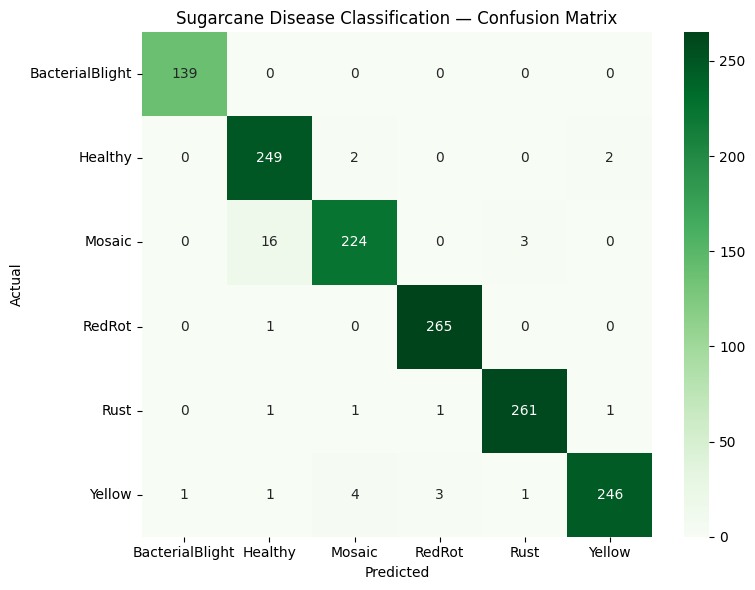


Final validation accuracy: 97.33 %


In [20]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
 
y_true = []
y_pred = []
 
for images, labels in val_ds_prepared:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
 
y_true = np.array(y_true)
y_pred = np.array(y_pred)
 
print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
 
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Sugarcane Disease Classification — Confusion Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/sugarcane_confusion_matrix.png", dpi=150)
plt.show()
 
print("\nFinal validation accuracy:", round(max(history3.history['val_accuracy']) * 100, 2), "%")

In [21]:
# ============================================================
# CELL 12 — Generate ALL files CropGuard AI backend needs
# ============================================================
import json
import shutil
import os

# ----------------------------------------------------------------
# 1) Build class_map.json in the SAME format as your main project
#    Maps: "sugarcane__<disease>" -> {"crop": "Sugarcane", "disease": "<Disease Name>"}
# ----------------------------------------------------------------

# Human-readable disease names for each folder/class name
DISEASE_DISPLAY_NAMES = {
    "BacterialBlight": "Bacterial Blight",
    "Healthy":         "Healthy",
    "Mosaic":          "Mosaic",
    "RedRot":          "Red Rot",
    "Rust":            "Rust",
    "Yellow":          "Yellow Disease",
}

# class_names here is already defined earlier in the notebook
# (the list returned by train_ds.class_names) — re-using it directly

sugarcane_class_map = {}
production_class_names = []   # the "crop__disease" style names, in SAME index order as class_names

for cls in class_names:
    disease_display = DISEASE_DISPLAY_NAMES.get(cls, cls)
    production_key = "sugarcane__" + cls.lower()
    production_class_names.append(production_key)
    sugarcane_class_map[production_key] = {
        "crop": "Sugarcane",
        "disease": disease_display
    }

print("=== sugarcane_class_map.json ===")
print(json.dumps(sugarcane_class_map, indent=2))

print("\n=== sugarcane_class_names.json (production naming, index order matches model output) ===")
print(json.dumps(production_class_names, indent=2))

# Save both files
with open("/kaggle/working/sugarcane_class_map.json", "w") as f:
    json.dump(sugarcane_class_map, f, indent=2)

with open("/kaggle/working/sugarcane_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)


# ----------------------------------------------------------------
# 2) Confirm final model files exist and show their sizes
# ----------------------------------------------------------------
files_to_check = [
    "/kaggle/working/sugarcane_final.keras",
    "/kaggle/working/sugarcane_best.keras",
    "/kaggle/working/sugarcane_class_map.json",
    "/kaggle/working/sugarcane_class_names.json",
    "/kaggle/working/sugarcane_confusion_matrix.png",
]

print("\n=== FINAL OUTPUT FILES (everything CropGuard AI needs for Sugarcane) ===")
for fpath in files_to_check:
    if os.path.exists(fpath):
        size_kb = os.path.getsize(fpath) / 1024
        print(f"  [OK] {fpath}  ({size_kb:.1f} KB)")
    else:
        print(f"  [MISSING] {fpath}")


# ----------------------------------------------------------------
# 3) Bundle everything into one zip for easy download
# ----------------------------------------------------------------
import zipfile

zip_path = "/kaggle/working/sugarcane_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for fpath in files_to_check:
        if os.path.exists(fpath):
            zf.write(fpath, arcname=os.path.basename(fpath))

print(f"\n=== Packaged everything into: {zip_path} ===")
print(f"Zip size: {os.path.getsize(zip_path) / (1024*1024):.1f} MB")
print("\nDownload this single zip file -- it has the model, both class JSON files, and the confusion matrix.")
print("\nIMPORTANT: After this finishes, go to Save Version -> Save & Run All (Commit)")
print("so these files are NOT lost when you close this session.")

=== sugarcane_class_map.json ===
{
  "sugarcane__bacterialblight": {
    "crop": "Sugarcane",
    "disease": "Bacterial Blight"
  },
  "sugarcane__healthy": {
    "crop": "Sugarcane",
    "disease": "Healthy"
  },
  "sugarcane__mosaic": {
    "crop": "Sugarcane",
    "disease": "Mosaic"
  },
  "sugarcane__redrot": {
    "crop": "Sugarcane",
    "disease": "Red Rot"
  },
  "sugarcane__rust": {
    "crop": "Sugarcane",
    "disease": "Rust"
  },
  "sugarcane__yellow": {
    "crop": "Sugarcane",
    "disease": "Yellow Disease"
  }
}

=== sugarcane_class_names.json (production naming, index order matches model output) ===
[
  "sugarcane__bacterialblight",
  "sugarcane__healthy",
  "sugarcane__mosaic",
  "sugarcane__redrot",
  "sugarcane__rust",
  "sugarcane__yellow"
]

=== FINAL OUTPUT FILES (everything CropGuard AI needs for Sugarcane) ===
  [OK] /kaggle/working/sugarcane_final.keras  (48242.0 KB)
  [OK] /kaggle/working/sugarcane_best.keras  (48242.0 KB)
  [OK] /kaggle/working/sugarcane_c